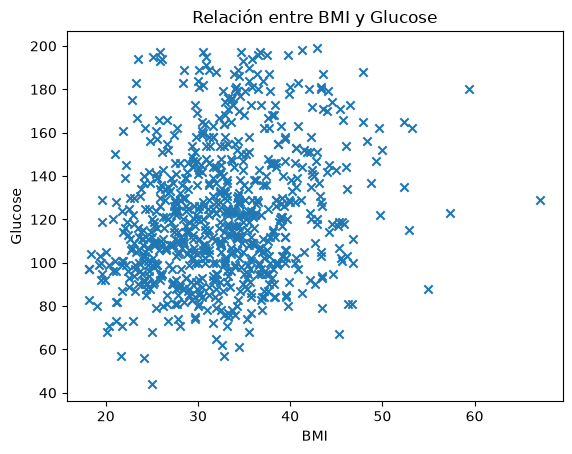

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# cargar el dataset
df = pd.read_csv('diabetes.csv')

# eliminar los valores 0 en las columnas 'BMI' y 'Glucose' 
df_limpio = df[(df['BMI'] != 0) & (df['Glucose'] != 0)]

# arrays de numpy para las columnas 'BMI' y 'Glucose'
x_raw = df_limpio['BMI'].to_numpy()
y_raw = df_limpio['Glucose'].to_numpy()

# graficar los datos
plt.scatter(x_raw, y_raw, marker='x')
plt.xlabel('BMI')
plt.ylabel('Glucose')
plt.title('Relación entre BMI y Glucose')
plt.show()

In [17]:
# función para calcular el costo
def compute_cost(x, y, w, b):
    m = x.shape[0]
    sum_cost = 0.0
    
    for i in range(m):
        f_wb = w * x[i] + b
        cost_i = (f_wb - y[i]) ** 2
        sum_cost += cost_i
        
    total_cost = (1 / (2 * m)) * sum_cost
    
    return total_cost

# función para calcular el gradiente
def compute_gradient(x, y, w, b):
    m = x.shape[0]
    dj_dw = 0.0
    dj_db = 0.0
    
    for i in range(m):
        f_wb = w * x[i] + b
        err = f_wb - y[i]
        dj_dw += err * x[i]
        dj_db += err
        
    dj_dw /= m
    dj_db /= m
    
    return dj_dw, dj_db

# función para realizar el descenso de gradiente
def gradient_descent(x, y, w_in, b_in, alpha, num_iters):
    w = w_in
    b = b_in
    J_history = []
    
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient(x, y, w, b)
        
        w -= alpha * dj_dw
        b -= alpha * dj_db
        
        J_history.append(compute_cost(x, y, w, b))
        
        if i % (num_iters / 10) == 0:
            print(f"Iteración {i}: Costo {J_history[-1]}")
    
    return w, b, J_history

Iteración 0: Costo 6384.040148174082
Iteración 100: Costo 612.4950806857183
Iteración 200: Costo 612.3470383015806
Iteración 300: Costo 612.1991250733581
Iteración 400: Costo 612.0513404743896
Iteración 500: Costo 611.9036843928168
Iteración 600: Costo 611.7561567168751
Iteración 700: Costo 611.6087573349005
Iteración 800: Costo 611.4614861353282
Iteración 900: Costo 611.3143430066841


Text(0.5, 1.0, 'Regresión Lineal: Glucose vs BMI')

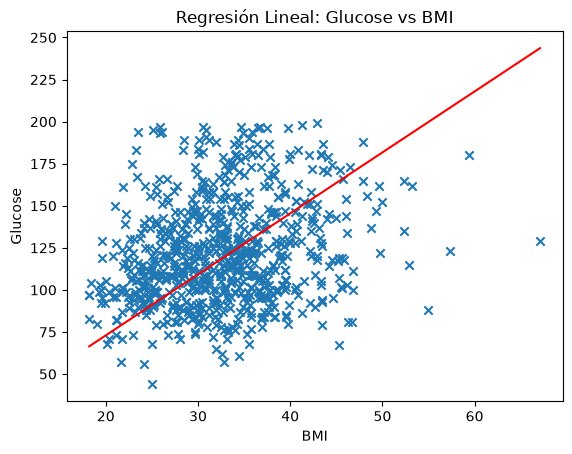

In [18]:
# Inicializar parámetros
w_inicial = 0.0
b_inicial = 0.0
alpha = 0.0001
num_iters = 1000

# Ejecutar el descenso de gradiente
w_final, b_final, J_historia = gradient_descent(x_raw, y_raw, w_inicial, b_inicial, alpha, num_iters)

# Graficar la línea de regresión
plt.scatter(x_raw, y_raw, marker='x', label='Datos')
x_line = np.linspace(min(x_raw), max(x_raw), 100)
y_line = w_final * x_line + b_final
plt.plot(x_line, y_line, color='red', label='Línea de Regresion')
plt.xlabel('BMI')
plt.ylabel('Glucose')
plt.title('Regresión Lineal: Glucose vs BMI')   

Text(0.5, 1.0, 'Historial de Costo durante el Entrenamiento')

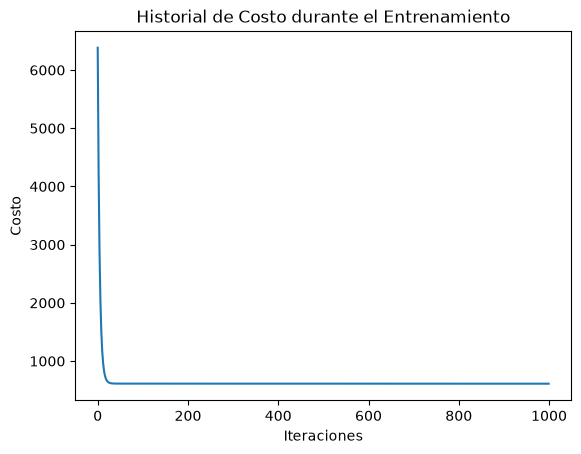

In [19]:
#Grafica de el historial de entrenamiento
plt.figure()
plt.plot(J_historia)
plt.xlabel('Iteraciones')
plt.ylabel('Costo')
plt.title('Historial de Costo durante el Entrenamiento')

In [27]:
# inputs de prueba al modelo final

print(f"Parámetros finales: w = {w_final}, b = {b_final}")
print(f"Predicción para BMI = 30: Glucose = {w_final * 30 + b_final}")
print(f"Predicción para BMI = 32: Glucose = {w_final * 32 + b_final}")
print(f"Predicción para BMI = 35: Glucose = {w_final * 35 + b_final}")
print(f"Predicción para BMI = 25: Glucose = {w_final * 25 + b_final}")
print(f"Predicción para BMI = 25: Glucose = {w_final * 27.5 + b_final}")

Parámetros finales: w = 3.6240892628493517, b = 0.49115480761151253
Predicción para BMI = 30: Glucose = 109.21383269309206
Predicción para BMI = 32: Glucose = 116.46201121879076
Predicción para BMI = 35: Glucose = 127.33427900733882
Predicción para BMI = 25: Glucose = 91.0933863788453
Predicción para BMI = 25: Glucose = 100.15360953596868


### Conclusion

Dado que el umbral clínico para prediabetes se establece a partir de 100mg/dL, el modelo sugiere que un incremento en la masa corporal eleva el riesgo metabólico, situando a los pacientes con un BMI de 27.5 en adelante dentro de la ventana de alerta prediabética (100 - 120mg/dL). Cabe recalcar que el modelo tiene un gran sesgo considerando que la diabetes es una enfermedad provocada por mas factores de los que se tuvieron en cuenta para el modelo.